# Data Science & AI/ML Practical Exam — Set A
**Campaign response prediction and audience segmentation**

Student: **Krisha Anghan** | Student ID: **10771** | Set: **A**

All five modules are in this one notebook:
1. Maths & Advanced Stats  2. Preprocessing & Feature Engineering  3. Supervised Learning  4. Unsupervised Learning  5. ANN

## 0. Setup

In [1]:
import json, random, sys, platform, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn, joblib
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, silhouette_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT, FIG, MOD = ROOT / "outputs", ROOT / "outputs" / "figures", ROOT / "models"
for p in (OUT, FIG, MOD):
    p.mkdir(parents=True, exist_ok=True)

# Generate the raw data with the supplied generator (unchanged) if it does not exist yet
RAW = ROOT / "data" / "raw" / "set_d.csv"
if not RAW.exists():
    subprocess.run([sys.executable, "src/generate_data.py"], cwd=ROOT, check=True)

versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
            "tensorflow": tf.__version__, "joblib": joblib.__version__, "seed": SEED}
json.dump(versions, open(OUT / "versions.json", "w"), indent=2)
print(versions)

{'python': '3.13.5', 'numpy': '2.5.3', 'pandas': '2.3.3', 'scipy': '1.16.1', 'scikit-learn': '1.8.0', 'matplotlib': '3.11.0', 'tensorflow': '2.21.0', 'joblib': '1.5.3', 'seed': 42}


## 2. Data Preprocessing — F1: Audit and Partition
(The audit and split come first because every module uses the 192 fit records.)

In [2]:
raw = pd.read_csv(RAW)                     # raw file is never modified
print("Raw shape:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nMissing values per column:\n", raw.isna().sum())
print("\nTarget counts (raw):\n", raw["response"].value_counts())

df = raw.drop_duplicates().reset_index(drop=True)      # remove exact duplicates BEFORE splitting
print("\nShape after removing duplicates:", df.shape)
assert len(df) == 300 and df["record_id"].is_unique, "Expected 300 unique records"
print("Verified: 300 unique records")
print("Target counts (clean):\n", df["response"].value_counts())

Raw shape: (305, 7)
Exact duplicate rows: 5

Missing values per column:
 record_id      0
visits        16
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64

Target counts (raw):
 response
1    177
0    128
Name: count, dtype: int64

Shape after removing duplicates: (300, 7)
Verified: 300 unique records
Target counts (clean):
 response
1    173
0    127
Name: count, dtype: int64


In [3]:
# 80/20 stratified train/test split, then 80/20 stratified fit/validation split (inside train)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["response"], random_state=SEED)
fit_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df["response"], random_state=SEED)
print("fit:", len(fit_df), "| validation:", len(val_df), "| test:", len(test_df))

# Save the record IDs of each partition
splits = pd.concat([
    pd.DataFrame({"record_id": fit_df["record_id"], "partition": "fit"}),
    pd.DataFrame({"record_id": val_df["record_id"], "partition": "validation"}),
    pd.DataFrame({"record_id": test_df["record_id"], "partition": "test"})])
splits.to_csv(OUT / "splits.csv", index=False)

# Prove the partitions are disjoint
fit_ids, val_ids, test_ids = set(fit_df.record_id), set(val_df.record_id), set(test_df.record_id)
assert fit_ids.isdisjoint(val_ids) and fit_ids.isdisjoint(test_ids) and val_ids.isdisjoint(test_ids)
assert len(fit_ids | val_ids | test_ids) == 300
print("Verified: partitions are disjoint and cover all 300 records")
print("Target balance  fit:", fit_df.response.mean().round(3), "val:", val_df.response.mean().round(3), "test:", test_df.response.mean().round(3))

fit: 192 | validation: 48 | test: 60
Verified: partitions are disjoint and cover all 300 records
Target balance  fit: 0.573 val: 0.583 test: 0.583


## 1. Maths & Advanced Stats
Only the **192 fit records** are used. Observed (non-imputed) values only.

### M1 — Descriptive statistics for `engagement`

{'n_observed': 192, 'mean': 51.00182291666667, 'median': 51.405, 'std_ddof1': 10.288960500356747}


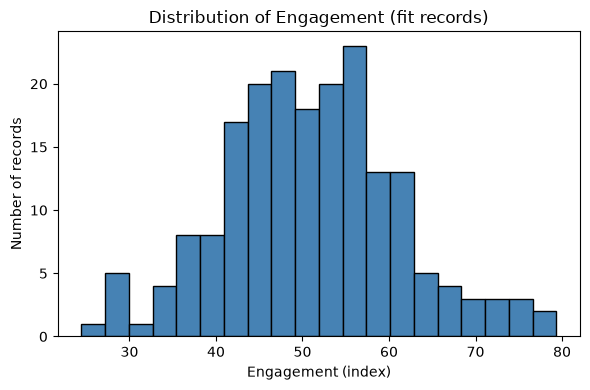

In [4]:
eng = fit_df["engagement"].dropna()
m1 = {"n_observed": int(eng.shape[0]), "mean": float(eng.mean()),
      "median": float(eng.median()), "std_ddof1": float(eng.std(ddof=1))}
print(m1)

plt.figure(figsize=(6, 4))
plt.hist(eng, bins=20, edgecolor="black", color="steelblue")
plt.title("Distribution of Engagement (fit records)")
plt.xlabel("Engagement (index)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG / "engagement_histogram.png", dpi=150)
plt.show()

### M2 — Statistical inference

In [5]:
g1 = fit_df.loc[fit_df.group == "G1", "engagement"].dropna()
g2 = fit_df.loc[fit_df.group == "G2", "engagement"].dropna()

# Welch two-sided t-test (does not assume equal variances), alpha = 0.05
t_stat, p_val = stats.ttest_ind(g1, g2, equal_var=False)
print(f"H0: mean engagement G1 = mean engagement G2")
print(f"H1: mean engagement G1 != mean engagement G2 (two-sided)")
print(f"n(G1) = {len(g1)}, n(G2) = {len(g2)}")
print(f"mean(G1) = {g1.mean():.3f}, mean(G2) = {g2.mean():.3f}")
print(f"Welch t = {t_stat:.4f}, p-value = {p_val:.4f}")
print("Decision at alpha=0.05:", "reject H0" if p_val < 0.05 else "fail to reject H0")

# 95% t-confidence interval for the overall mean of engagement
n = len(eng)
ci_low, ci_high = stats.t.interval(0.95, df=n - 1, loc=eng.mean(), scale=stats.sem(eng))
print(f"\n95% CI for overall mean engagement (n={n}): [{ci_low:.3f}, {ci_high:.3f}]")

m2 = {"n_G1": int(len(g1)), "n_G2": int(len(g2)), "mean_G1": float(g1.mean()), "mean_G2": float(g2.mean()),
      "welch_t": float(t_stat), "p_value": float(p_val), "alpha": 0.05,
      "reject_H0": bool(p_val < 0.05), "ci95_overall_mean_low": float(ci_low),
      "ci95_overall_mean_high": float(ci_high), "n_for_ci": int(n)}
json.dump({"descriptive_engagement": m1, "inference": m2}, open(OUT / "stats_summary.json", "w"), indent=2)

H0: mean engagement G1 = mean engagement G2
H1: mean engagement G1 != mean engagement G2 (two-sided)
n(G1) = 84, n(G2) = 108
mean(G1) = 51.615, mean(G2) = 50.525
Welch t = 0.7230, p-value = 0.4707
Decision at alpha=0.05: fail to reject H0

95% CI for overall mean engagement (n=192): [49.537, 52.466]


**Interpretation**
- *Welch t-test:* the group means are close (G1 ≈ 51.6, G2 ≈ 50.5) and the p-value (≈ 0.47) is above 0.05, so we **fail to reject H0**. There is no evidence in this sample of a difference in mean engagement between G1 and G2. This does not prove the means are equal.
- *95% CI:* we are 95% confident (in the repeated-sampling sense) that the overall mean engagement lies between about 49.5 and 52.5. The interval is not a statement that 95% of records fall in this range.
- *Assumptions:* records are assumed independent; the t-test and CI assume the sampling distribution of the mean is approximately normal. With n = 192 and a roughly symmetric histogram, the central limit theorem makes this reasonable. Welch's test does not need equal variances.

### M3 — Linear algebra (covariance and eigenvalues of engagement & visits)

In [6]:
sub = fit_df[["engagement", "visits"]].dropna()          # rows complete for both columns
X = sub.to_numpy()
n_c = X.shape[0]
Xc = X - X.mean(axis=0)                                   # manual centering
cov = Xc.T @ Xc / (n_c - 1)                               # manual sample covariance
print("Rows used:", n_c)
print("Covariance matrix:\n", cov)
print("Matches np.cov:", np.allclose(cov, np.cov(X, rowvar=False)))

eigvals, eigvecs = np.linalg.eigh(cov)                    # symmetric-matrix routine (ascending order)
share = eigvals.max() / eigvals.sum()
pc1 = eigvecs[:, np.argmax(eigvals)]
print("Eigenvalues:", eigvals)
print(f"Largest eigenvalue / sum of eigenvalues = {share:.4f}")
print("Principal direction (engagement, visits):", pc1)

json.dump({"rows_used": int(n_c), "covariance": cov.tolist(), "eigenvalues": eigvals.tolist(),
           "largest_eigenvalue_share": float(share), "principal_direction": pc1.tolist()},
          open(OUT / "linear_algebra.json", "w"), indent=2)

Rows used: 181
Covariance matrix:
 [[103.65708913   4.11811311]
 [  4.11811311 103.06117496]]
Matches np.cov: True
Eigenvalues: [ 99.23025399 107.4880101 ]
Largest eigenvalue / sum of eigenvalues = 0.5200
Principal direction (engagement, visits): [-0.73217627 -0.6811152 ]


**Interpretation:** the largest eigenvalue (≈ 107.5) divided by the sum (≈ 206.7) is **≈ 0.52**. The principal direction is the axis along which engagement and visits vary the most; its loadings are almost equal in size (≈ −0.73 and −0.68, the overall sign of an eigenvector is arbitrary), so it is roughly "engagement and visits moving together". But the covariance between them is small compared with each variance (≈ 4 vs ≈ 103), so the two variables are almost uncorrelated. The first direction therefore explains only about 52% of the variance, barely more than half, meaning these two variables carry mostly separate information and one cannot replace the other.

## 2. Data Preprocessing — F2: Fitted transformations and engineered feature
Everything is **fitted on the 192 fit records only** and then reused on validation and test.

In [7]:
num_cols = ["visits", "recency", "engagement", "spend"]
num_all = num_cols + ["engineered_feature"]

# Fit median imputer and one-hot encoder on fit data only
imputer = SimpleImputer(strategy="median").fit(fit_df[num_cols])
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(fit_df[["group"]])

def impute_and_engineer(d):
    """Median-impute numeric columns, then add engineered_feature on the ORIGINAL scale."""
    num = pd.DataFrame(imputer.transform(d[num_cols]), columns=num_cols, index=d.index)
    num["engineered_feature"] = num["engagement"] / (num["recency"] + 1)
    return num

# Fit the scaler on fit numeric features only (5 numeric columns, group dummies stay unscaled)
scaler = StandardScaler().fit(impute_and_engineer(fit_df)[num_all])

def preprocess(d):
    """Returns (model-ready features, unscaled imputed numeric features). Uses already-fitted objects."""
    num = impute_and_engineer(d)
    scaled = pd.DataFrame(scaler.transform(num[num_all]), columns=num_all, index=d.index)
    cat = pd.DataFrame(encoder.transform(d[["group"]]), columns=encoder.get_feature_names_out(["group"]), index=d.index)
    return pd.concat([scaled, cat], axis=1), num

X_fit, U_fit = preprocess(fit_df)
X_val, U_val = preprocess(val_df)
X_test, U_test = preprocess(test_df)
y_fit, y_val, y_test = fit_df["response"].to_numpy(), val_df["response"].to_numpy(), test_df["response"].to_numpy()

# Save the fitted preprocessing objects
joblib.dump({"imputer": imputer, "encoder": encoder, "scaler": scaler,
             "num_cols": num_cols, "num_all": num_all}, MOD / "preprocessing.joblib")
print("Imputer medians:", dict(zip(num_cols, imputer.statistics_.round(3))))
print("Scaler means:", dict(zip(num_all, scaler.mean_.round(3))))

Imputer medians: {'visits': np.float64(49.61), 'recency': np.float64(50.6), 'engagement': np.float64(51.405), 'spend': np.float64(50.595)}
Scaler means: {'visits': np.float64(49.446), 'recency': np.float64(50.457), 'engagement': np.float64(51.002), 'spend': np.float64(50.522), 'engineered_feature': np.float64(1.026)}


### F3 — Leakage evidence

In [8]:
print("Transformed shapes -> fit:", X_fit.shape, "| validation:", X_val.shape, "| test:", X_test.shape)
print("Feature names:", list(X_fit.columns))
finite = all(np.isfinite(a.to_numpy()).all() for a in (X_fit, X_val, X_test))
print("All transformed values finite:", finite)
print("Scaled fit means ~0:", X_fit[num_all].mean().round(6).to_dict())
print("Target / record_id in features:", [c for c in X_fit.columns if c in ("response", "record_id")])

audit = {"raw_shape": list(raw.shape), "duplicates_removed": int(raw.duplicated().sum()),
         "unique_records": int(len(df)),
         "missing_raw": raw.isna().sum().to_dict(),
         "partition_sizes": {"fit": len(fit_df), "validation": len(val_df), "test": len(test_df)},
         "transformed_shapes": {"fit": list(X_fit.shape), "validation": list(X_val.shape), "test": list(X_test.shape)},
         "feature_names": list(X_fit.columns), "all_finite": bool(finite),
         "engineered_feature": "engagement / (recency + 1), after imputation, before scaling"}
json.dump(audit, open(OUT / "preprocessing_audit.json", "w"), indent=2)

Transformed shapes -> fit: (192, 7) | validation: (48, 7) | test: (60, 7)
Feature names: ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']
All transformed values finite: True
Scaled fit means ~0: {'visits': 0.0, 'recency': -0.0, 'engagement': -0.0, 'spend': -0.0, 'engineered_feature': -0.0}
Target / record_id in features: []


**Why these exclusions prevent leakage**
- **Target (`response`)** is what we predict. If it entered the features (or the engineered feature), the model would "see the answer" and the metrics would be unrealistic.
- **`record_id`** is only an identifier with no real meaning. A model could memorise it, and it would not generalise to new customers.
- **Test statistics** (medians, means, standard deviations) must not be used for imputation or scaling. Otherwise information from the test set would leak into training and make the test score optimistic. All transformers were fitted on the 192 fit rows only and then reused unchanged on validation and test.
- The engineered feature `engagement / (recency + 1)` is computed after imputation and before scaling, from predictors only.

## 3. Supervised Learning
- **Target:** `response` (1 = responded)
- **Predictors:** visits, recency, engagement, spend, engineered_feature (scaled) + group_G1, group_G2 (one-hot)
- **Not used:** `record_id`, target in features
- **Split:** fixed IDs in `outputs/splits.csv` (192 fit / 48 validation / 60 test)

### S1 — Baseline and logistic regression

In [9]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_fit, y_fit)       # majority-class baseline
logreg = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_fit, y_fit)
print("Baseline always predicts class:", dummy.classes_[np.argmax(dummy.class_prior_)])
print("Logistic coefficients:")
print(pd.Series(logreg.coef_[0], index=X_fit.columns).round(3))

Baseline always predicts class: 1
Logistic coefficients:
visits                0.875
recency              -0.739
engagement            0.868
spend                 0.613
engineered_feature    0.840
group_G1             -0.119
group_G2              0.119
dtype: float64


### S2 — Holdout evaluation (60 untouched test records, threshold 0.5)

                     accuracy  precision  recall      f1
Baseline (majority)    0.5833     0.5833  1.0000  0.7368
Logistic Regression    0.8167     0.8333  0.8571  0.8451


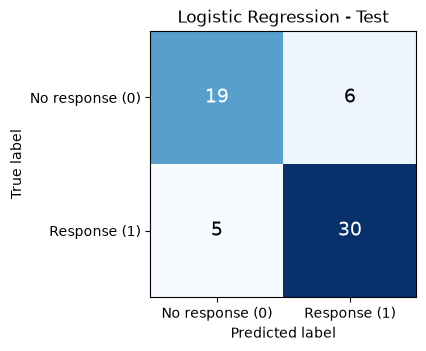

In [10]:
def get_metrics(y_true, y_pred):
    # zero_division=0: if a model never predicts class 1, precision is undefined -> reported as 0
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

def plot_cm(y_true, y_pred, title, path):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["No response (0)", "Response (1)"]); ax.set_yticklabels(["No response (0)", "Response (1)"])
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()
    return cm

THRESH = 0.5
dummy_pred = dummy.predict(X_test)
lr_prob = logreg.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= THRESH).astype(int)

res = {"Baseline (majority)": get_metrics(y_test, dummy_pred),
       "Logistic Regression": get_metrics(y_test, lr_pred)}
print(pd.DataFrame(res).T.round(4))

cm_lr = plot_cm(y_test, lr_pred, "Logistic Regression - Test", FIG / "confusion_matrix_logistic.png")
pd.DataFrame(cm_lr, index=["true_0", "true_1"], columns=["pred_0", "pred_1"]).to_csv(OUT / "confusion_matrix_logistic.csv")

pd.DataFrame({"record_id": test_df["record_id"].to_numpy(), "true_label": y_test,
              "predicted_label": lr_pred, "prob_class1": lr_prob}).to_csv(OUT / "predictions_logistic.csv", index=False)

### S3 — Interpretation
**Error consequences.**
- A **false positive** means we predict a customer will respond but they do not: marketing budget is spent on someone who will not convert (a cost, and possible annoyance).
- A **false negative** means we predict no response for someone who would have responded: we miss a likely buyer and lose potential revenue. If a contact is cheap and a response is valuable, false negatives are usually the costlier error, so recall deserves attention.

**Is the classifier useful?** The majority-class baseline gets accuracy 0.583 because 58% of the test records are responders, and it reaches recall 1.0 only by predicting "response" for everybody, so it never separates anyone. Logistic regression reaches accuracy 0.817, precision 0.833, recall 0.857 and F1 0.845. That is a clear improvement over the baseline in accuracy (+0.23) and precision (+0.25) while keeping high recall, so the model does add useful signal. The limitation is that this is one holdout of only 60 records: one record changes accuracy by about 1.7 percentage points, so the numbers are uncertain and this is not evidence of deployment readiness.

## 4. Unsupervised Learning
K-Means on the 5 scaled numeric fit features (`visits, recency, engagement, spend, engineered_feature`).
Group dummies, the target and the ID are excluded. Test data and labels are not used.

### U1 — K-Means and selection of k

c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\Meet Anghan\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Meet Anghan\AppData\Loc

   k   inertia  silhouette
0  2  713.0304      0.2259
1  3  613.5511      0.1872
2  4  541.6453      0.1907
Chosen k = 2


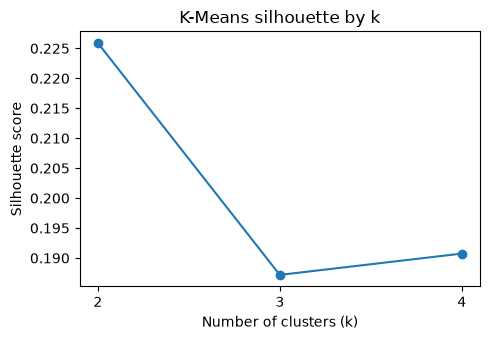

In [11]:
Xk = X_fit[num_all]
rows = []
for k in (2, 3, 4):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xk)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xk, km.labels_)})
kscores = pd.DataFrame(rows)
print(kscores.round(4))
kscores.to_csv(OUT / "kmeans_scores.csv", index=False)

# choose highest silhouette; ties (to 6 decimals) go to the smaller k
kscores["sil_r"] = kscores["silhouette"].round(6)
best_k = int(kscores.sort_values(["sil_r", "k"], ascending=[False, True]).iloc[0]["k"])
kscores = kscores.drop(columns="sil_r")
print("Chosen k =", best_k)

plt.figure(figsize=(5, 3.5))
plt.plot(kscores["k"], kscores["silhouette"], marker="o")
plt.xticks([2, 3, 4]); plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette score")
plt.title("K-Means silhouette by k"); plt.tight_layout()
plt.savefig(FIG / "kmeans_silhouette.png", dpi=150); plt.show()

### U2 — Segment profiles

In [12]:
final_km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(Xk)
profile = U_fit[num_all].copy()                   # original-scale (imputed) values, easier to interpret
profile["cluster"] = final_km.labels_
cluster_profile = profile.groupby("cluster").mean().round(2)
cluster_profile.insert(0, "size", profile.groupby("cluster").size())
print(cluster_profile)
cluster_profile.to_csv(OUT / "cluster_profiles.csv")

         size  visits  recency  engagement  spend  engineered_feature
cluster                                                              
0         109   49.37    55.25       46.09  50.18                0.83
1          83   49.54    44.17       57.45  50.97                1.29


**Cluster names and actions** (cluster IDs are arbitrary labels that can change with the random seed or ordering; they are not the same as the target classes 0/1 and were chosen without looking at the target):

| Cluster | Profile | Name | Practical action |
|---|---|---|---|
| 0 | Lower engagement (≈ 46), higher recency (≈ 55, i.e. longer since last activity) | **Cooling / lapsing customers** | Send a re-activation offer or reminder campaign |
| 1 | Higher engagement (≈ 57), lower recency (≈ 44, i.e. recently active) | **Active engaged customers** | Offer loyalty benefits or early access to deepen the relationship |

Visits and spend are almost the same in both clusters, so the split is driven mainly by engagement and recency. Note that k = 2 had the highest silhouette (≈ 0.23), but this is a low value, which means the segments overlap and the structure is weak; treat them as a rough grouping, not clearly separated natural groups.

## 5. Deep Learning up to ANN
### D1 — Architecture and compilation

In [13]:
tf.keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    layers.Input(shape=(X_fit.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()
trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print("Trainable parameters:", trainable)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 273


**Output / loss choice:** the target is binary, so the last layer is one **sigmoid** unit that outputs P(response = 1) between 0 and 1.
**Binary cross-entropy** is the matching loss: it penalises confident wrong probabilities and is the log-likelihood of a Bernoulli outcome.

### D2 — Training with validation and early stopping

Random seed: 42 | epochs actually run: 50 | best epoch (restored): 50
Final train loss: 0.3931 | final val loss: 0.3144


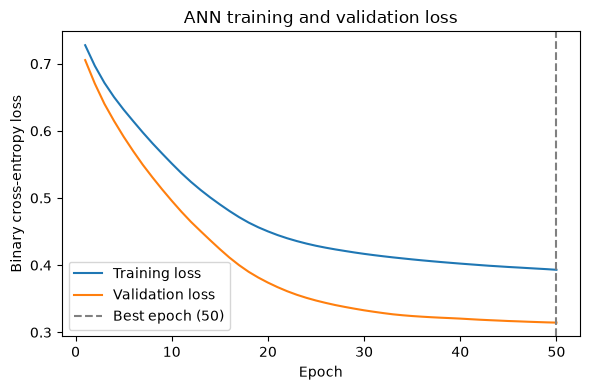

In [14]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(X_fit.to_numpy("float32"), y_fit,
                    validation_data=(X_val.to_numpy("float32"), y_val),
                    epochs=50, batch_size=16, callbacks=[early], verbose=0)

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Random seed: {SEED} | epochs actually run: {epochs_run} | best epoch (restored): {best_epoch}")
print(f"Final train loss: {history.history['loss'][-1]:.4f} | final val loss: {history.history['val_loss'][-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs_run + 1), history.history["loss"], label="Training loss")
plt.plot(range(1, epochs_run + 1), history.history["val_loss"], label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy loss"); plt.title("ANN training and validation loss")
plt.legend(); plt.tight_layout(); plt.savefig(FIG / "ann_loss_curves.png", dpi=150); plt.show()
pd.DataFrame(history.history).assign(epoch=range(1, epochs_run + 1)).to_csv(OUT / "ann_history.csv", index=False)

**Learning-curve discussion.** Both training and validation loss fall steadily and the validation loss is still decreasing at the last epoch, so early stopping (patience 5) never triggered and the model used the full 50 epochs (best epoch = 50). This points to **mild underfitting / not yet converged** rather than overfitting: there is no point where validation loss turns upward while training loss keeps falling. Validation loss is lower than training loss, which is plausible with a small 48-record validation set and because training loss is averaged over each epoch while weights are still changing. More epochs might help, but the exam fixes the limit at 50 and we do not tune on the test set.

### D3 — Test evaluation and comparison (same 60 test records)

                     accuracy  precision  recall      f1
model                                                   
Baseline (majority)    0.5833     0.5833  1.0000  0.7368
Logistic Regression    0.8167     0.8333  0.8571  0.8451
ANN                    0.8333     0.8378  0.8857  0.8611


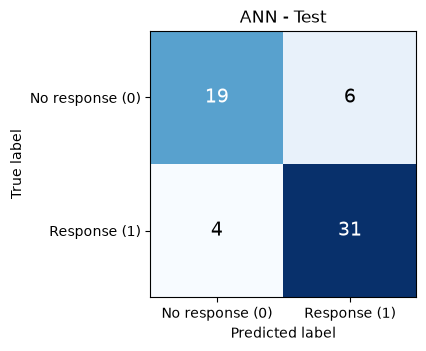

In [15]:
ann_prob = model.predict(X_test.to_numpy("float32"), verbose=0).ravel()
ann_pred = (ann_prob >= THRESH).astype(int)
res["ANN"] = get_metrics(y_test, ann_pred)

comparison = pd.DataFrame(res).T
comparison.index.name = "model"
print(comparison.round(4))
comparison.to_csv(OUT / "metrics_comparison.csv")

cm_ann = plot_cm(y_test, ann_pred, "ANN - Test", FIG / "confusion_matrix_ann.png")
pd.DataFrame(cm_ann, index=["true_0", "true_1"], columns=["pred_0", "pred_1"]).to_csv(OUT / "confusion_matrix_ann.csv")

pd.DataFrame({"record_id": test_df["record_id"].to_numpy(), "true_label": y_test,
              "predicted_label": ann_pred, "prob_class1": ann_prob}).to_csv(OUT / "predictions_ann.csv", index=False)

# Save the trained ANN
model.save(MOD / "ann_model.keras")
model.save_weights(MOD / "ann.weights.h5")

**Comparison and model preference.** On the same 60 test records the ANN reached F1 ≈ 0.861 vs ≈ 0.845 for logistic regression (accuracy 0.833 vs 0.817). That is a difference of about one correctly classified record, which is well within the noise of such a small holdout, so I do **not** claim the ANN is truly better. I would **prefer logistic regression** here: it performs about equally, trains instantly, is stable, and its coefficients are directly interpretable (engagement, visits, spend and the engineered feature push the response probability up; recency pushes it down). The ANN would only be worth its extra complexity if a larger validation showed a consistent gain.

## Reconciliation and reproducibility checks

In [16]:
# 1) Metrics recomputed from the SAVED prediction files must equal the reported metrics
p_lr = pd.read_csv(OUT / "predictions_logistic.csv")
p_ann = pd.read_csv(OUT / "predictions_ann.csv")
assert (p_lr["record_id"].to_numpy() == p_ann["record_id"].to_numpy()).all(), "Models must use identical test IDs"
assert set(p_lr["record_id"]) == set(splits.loc[splits.partition == "test", "record_id"])
for name, p in (("Logistic Regression", p_lr), ("ANN", p_ann)):
    m = get_metrics(p["true_label"], p["predicted_label"])
    assert all(abs(m[k] - res[name][k]) < 1e-12 for k in m), f"{name} metrics do not match saved predictions"
print("OK: test metrics match saved predictions; both models use the same 60 test IDs")

# 2) Saved model + preprocessing can be loaded and reproduce the predictions
loaded = keras.models.load_model(MOD / "ann_model.keras")
prep = joblib.load(MOD / "preprocessing.joblib")
print("Reloaded ANN predictions identical:",
      np.allclose(loaded.predict(X_test.to_numpy("float32"), verbose=0).ravel(), ann_prob, atol=1e-6))
print("Saved preprocessing keys:", list(prep.keys()))

OK: test metrics match saved predictions; both models use the same 60 test IDs
Reloaded ANN predictions identical: True
Saved preprocessing keys: ['imputer', 'encoder', 'scaler', 'num_cols', 'num_all']


## Final findings
**Two numerical findings**
1. Logistic regression reached test accuracy **0.817** and F1 **0.845**, versus **0.583** accuracy for the majority-class baseline (60 untouched test records).
2. Mean engagement did not differ significantly between G1 and G2 (Welch t = 0.72, p = 0.47); the overall mean engagement was ≈ 51.0 with a 95% CI of ≈ [49.5, 52.5].

**Recommendation:** use the logistic regression model to prioritise customers for the campaign (it matches the ANN and is easier to explain), and use the two segments (cooling vs active) to tailor messages.

**Limitation:** all results come from 300 synthetic records and a single 60-record holdout, so metrics carry wide uncertainty. No causal or deployment-readiness claim is made.